# 02 · Model Training and Checkpoint Selection

**Objective.** Fine-tune an ImageNet-pretrained ResNet18 for binary cat-vs-dog classification and persist a reproducible checkpoint for explanation analysis.

## Protocol

- **Backbone:** ResNet18 with a new two-way linear head.
- **Initialization:** ImageNet weights (`ResNet18_Weights.DEFAULT`).
- **Optimizer:** AdamW, `lr = 3e-4`, `weight_decay = 1e-4`.
- **Scheduler:** `ReduceLROnPlateau` on validation loss (`factor = 0.3`, `patience = 1`).
- **Early stopping:** patience 3 epochs on validation loss.
- **Selection criterion:** lowest validation loss; the corresponding state dict is saved.
- **Final metrics:** accuracy, precision, recall, F1, ROC-AUC, and a confusion matrix on the official test split.

## Artifacts

- `checkpoints/resnet18_best.pth`
- `experiments/results/training_history.csv`
- `experiments/results/test_metrics.json`
- `experiments/results/training_config.json`
- `figures/training_history.png`
- `figures/test_confusion_matrix.png`

> **Reproducibility note.** Training is delegated to `src.train` so that the CLI and the notebook share one implementation. Set `RUN_TRAINING = False` to reuse an existing checkpoint.

## Environment and configuration

The runtime is recorded explicitly because checkpoint compatibility depends on the PyTorch and torchvision versions. The seed is fixed before any data loader or model is created.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import subprocess
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image as DisplayImage, display

from src.config import ExperimentConfig
from src.utils import device, seed_everything

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})

config = ExperimentConfig()
config.create_directories()
seed_everything(config.seed)

print(f"Project root : {PROJECT_ROOT}")
print(f"Device       : {device()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Seed         : {config.seed}")

Project root : C:\Users\hp\Desktop\Nouveau dossier (3)
Device       : cpu
PyTorch      : 2.14.0+cpu
Seed         : 42


In [2]:
config_view = pd.Series({
    "image_size": config.image_size,
    "batch_size": config.batch_size,
    "epochs": config.epochs,
    "learning_rate": config.learning_rate,
    "weight_decay": config.weight_decay,
    "patience": config.patience,
    "seed": config.seed,
    "num_classes": config.num_classes,
    "device": str(device()),
}, name="value").to_frame()
config_view

,value
image_size,224
batch_size,32
epochs,10
learning_rate,0.0003
weight_decay,0.0001
patience,3
seed,42
num_classes,2
device,cpu


## Data loaders

The loaders are rebuilt here only to verify sizes and batch counts. Training itself uses the identical function inside `src.train`.

In [3]:
from src.data.oxford_pets import load_oxford_pets

train_loader, validation_loader, test_loader = load_oxford_pets(
    config.data_root,
    config.image_size,
    config.batch_size,
    config.num_workers,
    seed=config.seed,
)

loader_summary = pd.DataFrame([
    {"split": "train", "batches": len(train_loader), "samples": len(train_loader.dataset), "shuffle": True},
    {"split": "validation", "batches": len(validation_loader), "samples": len(validation_loader.dataset), "shuffle": False},
    {"split": "test", "batches": len(test_loader), "samples": len(test_loader.dataset), "shuffle": False},
])
loader_summary

,split,batches,samples,shuffle
0,train,98,3128,True
1,validation,18,552,False
2,test,115,3669,False


## Model

Only the final fully connected layer is replaced; all other layers retain ImageNet weights. The number of trainable parameters is reported to document the capacity of the fine-tuning setup.

In [4]:
from src.models.resnet import build_resnet18

model = build_resnet18(config.num_classes)
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
total_parameters = sum(parameter.numel() for parameter in model.parameters())

model_summary = pd.Series({
    "architecture": "ResNet18",
    "pretrained": True,
    "num_classes": config.num_classes,
    "total_parameters": total_parameters,
    "trainable_parameters": trainable_parameters,
    "classification_head": str(model.fc),
}, name="value").to_frame()
model_summary

,value
architecture,ResNet18
pretrained,True
num_classes,2
total_parameters,11177538
trainable_parameters,11177538
classification_head,"Linear(in_features=512, out_features=2, bias=T..."


## Training

Training is launched as a subprocess so that the notebook and the command line execute exactly the same code path. Set `RUN_TRAINING = False` to reuse an existing checkpoint without retraining.

Expected runtime depends on hardware: a modern GPU completes 10 epochs quickly; CPU execution is supported but slower.

In [5]:
checkpoint_path = config.checkpoint_root / "resnet18_best.pth"
RUN_TRAINING = not checkpoint_path.exists()

if RUN_TRAINING:
    command = [sys.executable, "-m", "src.train", "--epochs", str(config.epochs)]
    completed = subprocess.run(command, cwd=PROJECT_ROOT)
    if completed.returncode != 0:
        raise RuntimeError("Training failed. Inspect the subprocess output above.")
else:
    print(f"Checkpoint found at {checkpoint_path}; skipping training.")

Checkpoint found at checkpoints\resnet18_best.pth; skipping training.


## Training history

The history table is written by `src.train`. It contains per-epoch training and validation loss and accuracy, which are sufficient to diagnose underfitting, overfitting, and unstable optimisation.

In [6]:
history_path = config.output_root / "training_history.csv"
if not history_path.exists():
    raise FileNotFoundError("Training history is missing. Set RUN_TRAINING = True or run `python -m src.train`.")

history = pd.read_csv(history_path)
history

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
0,1,0.124430,0.950767,0.087475,0.969203
1,2,0.067534,0.975064,0.085271,0.967391
2,3,0.029229,0.988811,0.041441,0.983696
3,4,0.050509,0.984974,0.048182,0.980072
4,5,0.019444,0.994246,0.071282,0.972826
5,6,0.025596,0.993286,0.046379,0.980072


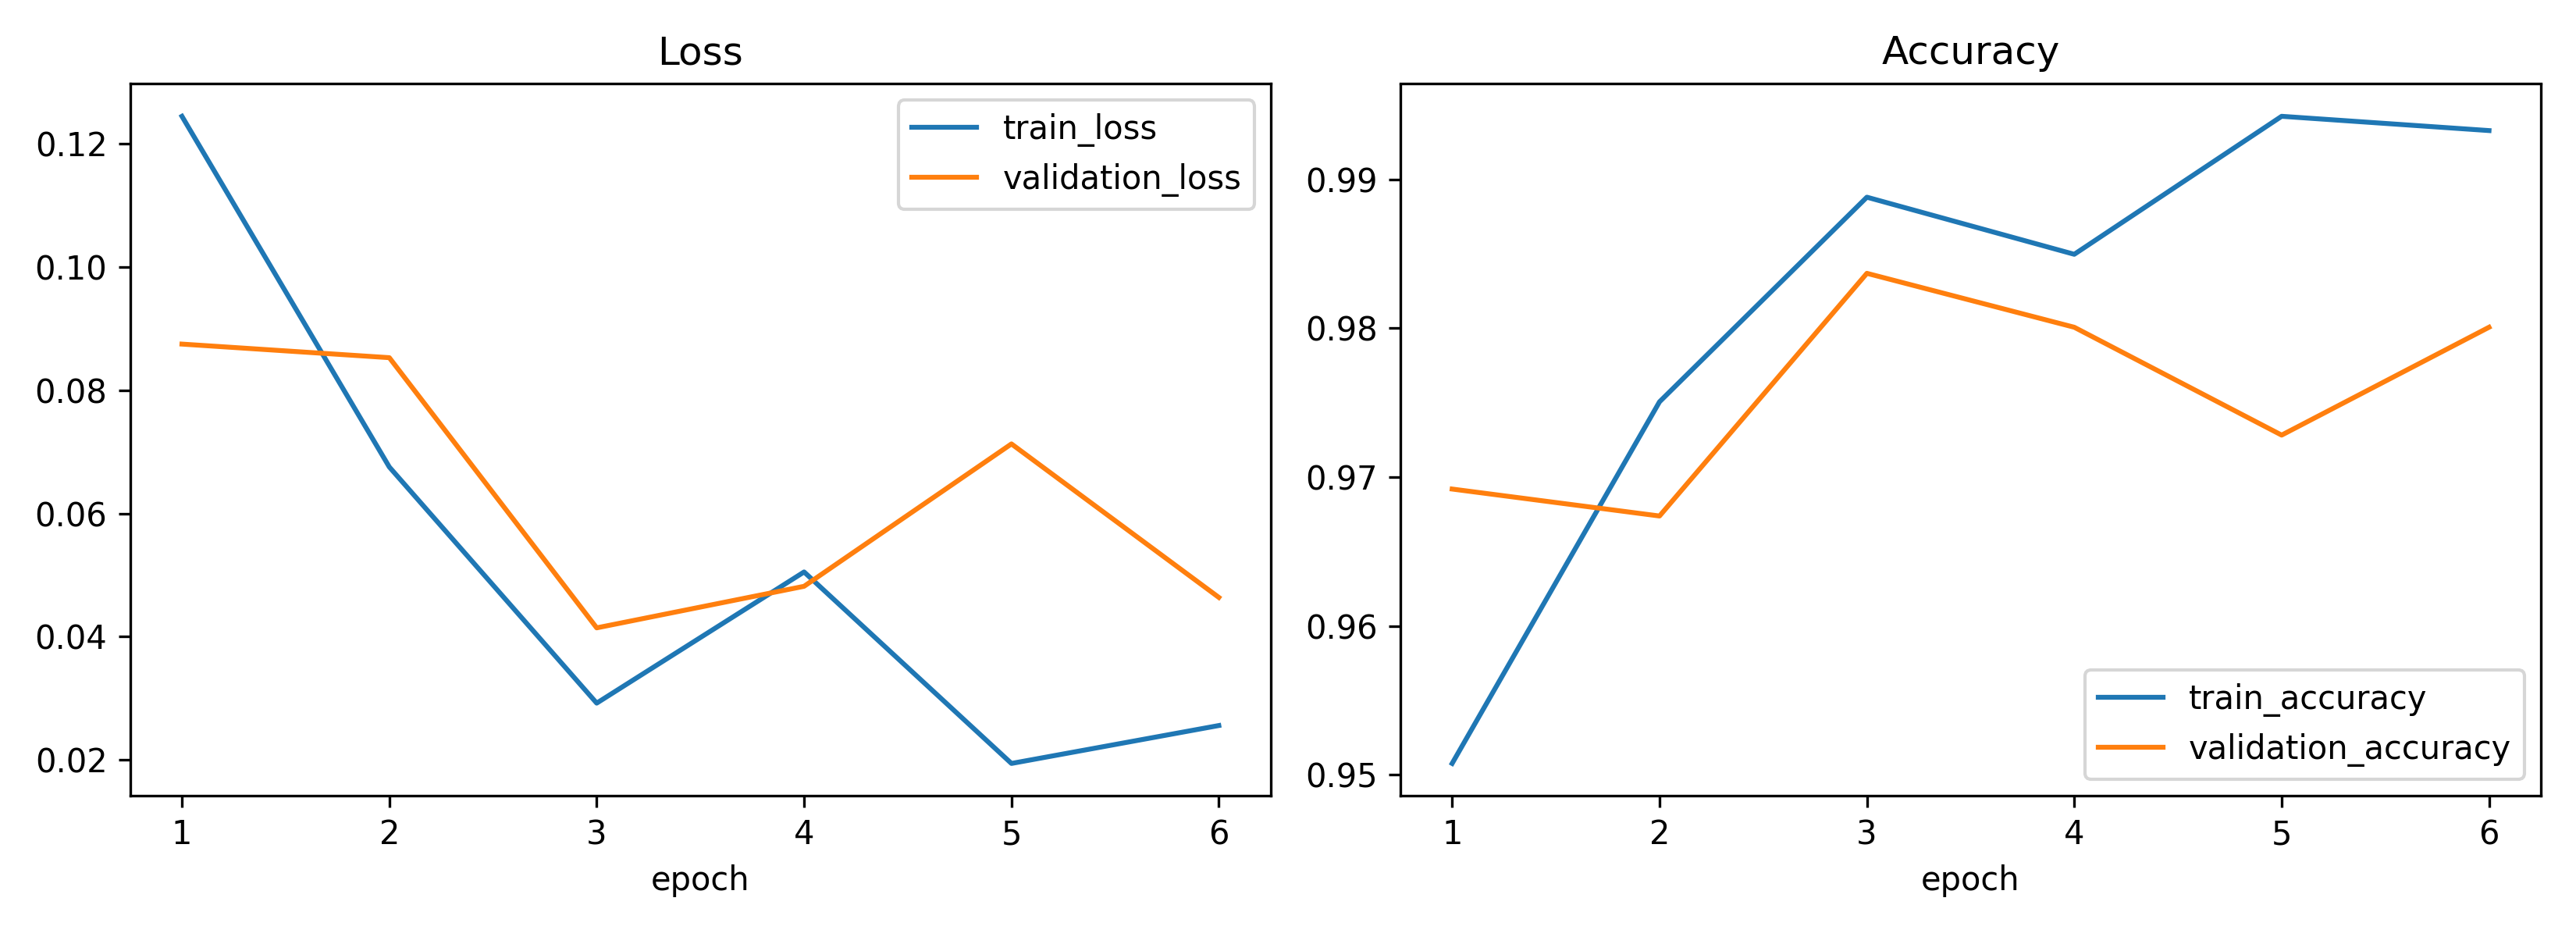

In [7]:
from src.visualization.plots import plot_training_history

plot_training_history(history, Path("figures") / "training_history.png")
display(DisplayImage(filename=str(Path("figures") / "training_history.png")))

## Held-out test metrics

The checkpoint is selected on validation loss. The test metrics below are reported once and should not be used for further model selection.

In [8]:
metrics_path = config.output_root / "test_metrics.json"
if not metrics_path.exists():
    raise FileNotFoundError("Test metrics are missing. Run training first.")

metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
scalar_metrics = pd.Series(
    {key: value for key, value in metrics.items() if not isinstance(value, list)},
    name="value",
).to_frame()
scalar_metrics

,value
accuracy,0.980649
precision,0.980884
recall,0.990748
f1,0.985791
roc_auc,0.998135


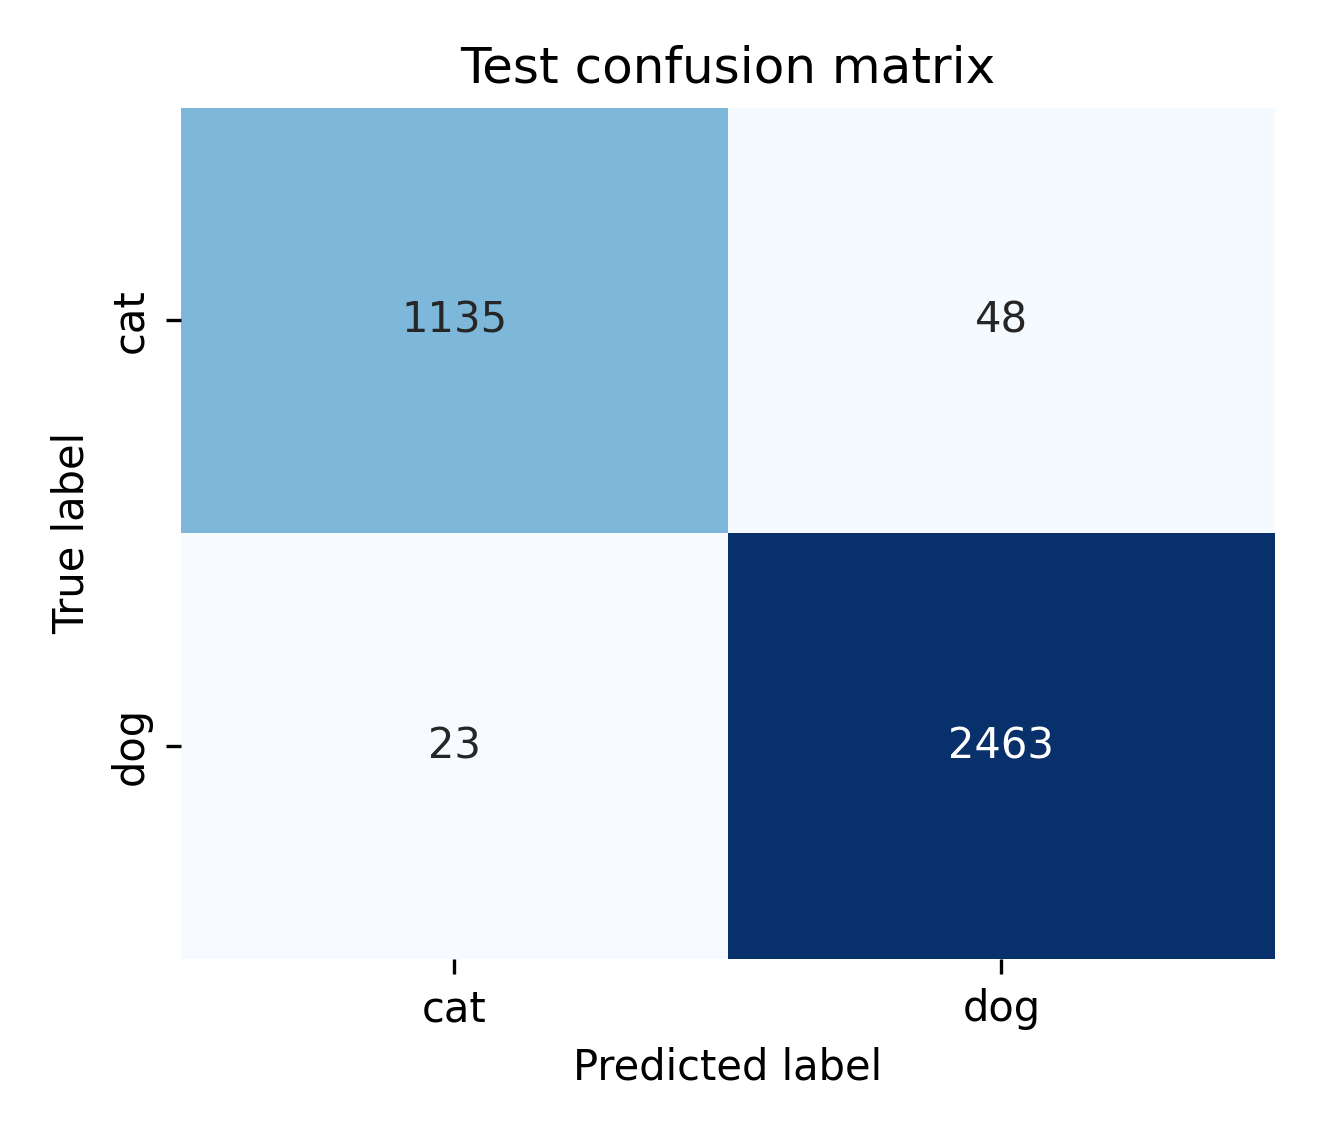

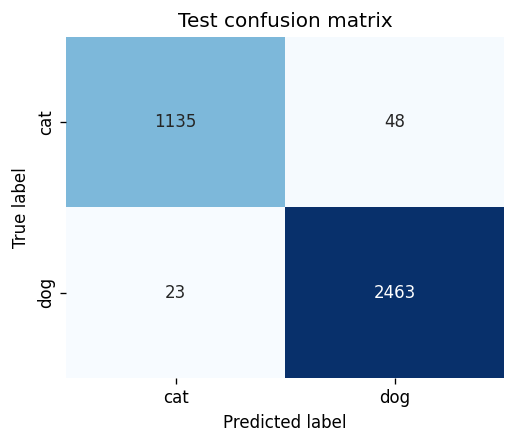

In [9]:
confusion = np.asarray(metrics["confusion_matrix"])
figure, axis = plt.subplots(figsize=(4.4, 3.8))
sns.heatmap(
    confusion, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["cat", "dog"], yticklabels=["cat", "dog"], ax=axis,
)
axis.set(title="Test confusion matrix", xlabel="Predicted label", ylabel="True label")
figure.tight_layout()
figure.savefig(Path("figures") / "test_confusion_matrix.png", dpi=300)
display(DisplayImage(filename=str(Path("figures") / "test_confusion_matrix.png")))

## Checkpoint inspection

The checkpoint stores the best model state and the training history. Recording its size, modification time, and entry count makes artifact provenance auditable.

In [10]:
checkpoint_path = config.checkpoint_root / "resnet18_best.pth"
if not checkpoint_path.exists():
    raise FileNotFoundError("Checkpoint not found. Run training or execute `python -m src.train`.")

checkpoint = torch.load(checkpoint_path, map_location="cpu")
checkpoint_info = pd.Series({
    "path": str(checkpoint_path),
    "size_mb": round(checkpoint_path.stat().st_size / 1e6, 2),
    "last_modified": datetime.fromtimestamp(checkpoint_path.stat().st_mtime).isoformat(timespec="seconds"),
    "state_dict_entries": len(checkpoint["model_state_dict"]),
    "epochs_recorded": len(checkpoint.get("history", [])),
}, name="value").to_frame()
checkpoint_info

,value
path,checkpoints\resnet18_best.pth
size_mb,44.79
last_modified,2026-11-07T21:47:16
state_dict_entries,122
epochs_recorded,3


## Interpretation guide and next steps

- **Training curves.** Validation loss should track training loss without a widening gap. A rising validation loss with falling training loss indicates overfitting and justifies early stopping.
- **Confusion matrix.** Inspect class-specific errors rather than accuracy alone. Asymmetric errors matter for downstream explanation analysis because the explanation methods are conditioned on the predicted class.
- **Checkpoint integrity.** The metadata above should match the run configuration. If not, delete stale artifacts and retrain.

Proceed to `03_explainability_methods.ipynb`.